## Loss del VAE

La loss è `reconstruction_MSE + beta * KL`; in valutazione usiamo `z = mu` per risultati riproducibili.


## Interpretazione

Il VAE può regolarizzare lo spazio latente e produrre immagini più morbide; il confronto richiede lo stesso protocollo.


# 3. Esperimenti e confronto con VAE

Questo notebook confronta configurazioni e introduce il conditional denoising VAE: l’ingresso è rumoroso, mentre il target resta l’immagine pulita.


## Loss del VAE

La loss è `reconstruction_MSE + beta * KL`. Il termine KL regolarizza lo spazio latente verso una normale standard. Durante il test usiamo `z = mu`, non un campione casuale, per ottenere metriche riproducibili.


## Interpretazione

Un VAE può ricostruire immagini più regolari ma perdere dettaglio pixel-level rispetto all’AutoEncoder. Il confronto è significativo solo mantenendo uguali split, rumore, budget di training e criterio di checkpoint.


# 3. Esperimenti e VAE

Usare lo stesso split e la stessa degradazione rende il confronto corretto.


In [5]:
from pathlib import Path

import sys

import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from torchvision.datasets import EuroSAT

ROOT = Path.cwd()
while not (ROOT / "README.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from eurosat_denoising.utils import *
from eurosat_denoising.models import ConvVAE
from eurosat_denoising.training import evaluate

seed_everything(42)

DATA = ROOT / "data"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset = EuroSAT(DATA, download=False)
n = len(dataset)
indices = list(range(len(dataset)))
labels = list(dataset.targets)
train_idx, remainder, _, remainder_labels = train_test_split(
    indices, labels, test_size=0.30, random_state=42, stratify=labels
)
val_idx, test_idx = train_test_split(
    remainder, test_size=0.5, random_state=42, stratify=remainder_labels
)

corrupt = lambda image: add_gaussian_noise(image, 0.15)
train = NoisyCleanDataset(dataset, train_idx, corrupt)
val = NoisyCleanDataset(dataset, val_idx, corrupt, seed=1000)
test = NoisyCleanDataset(dataset, test_idx, corrupt, seed=2000)
tr = DataLoader(train, 128, shuffle=True)
va = DataLoader(val, 128)
te = DataLoader(test, 128)


In [6]:
# Carichiamo il VAE gia' addestrato (checkpoint prodotto dalla CLI).
vae = ConvVAE().to(DEVICE)
vae_path = OUT / "vae_best.pt"
if vae_path.exists():
    vae.load_state_dict(torch.load(vae_path, map_location=DEVICE))


VAE test: {'mse': 0.003821675100444276, 'psnr': 24.177463054656982, 'ssim_mean': 0.6058871166812785, 'ssim_std': 0.23209042847156525}


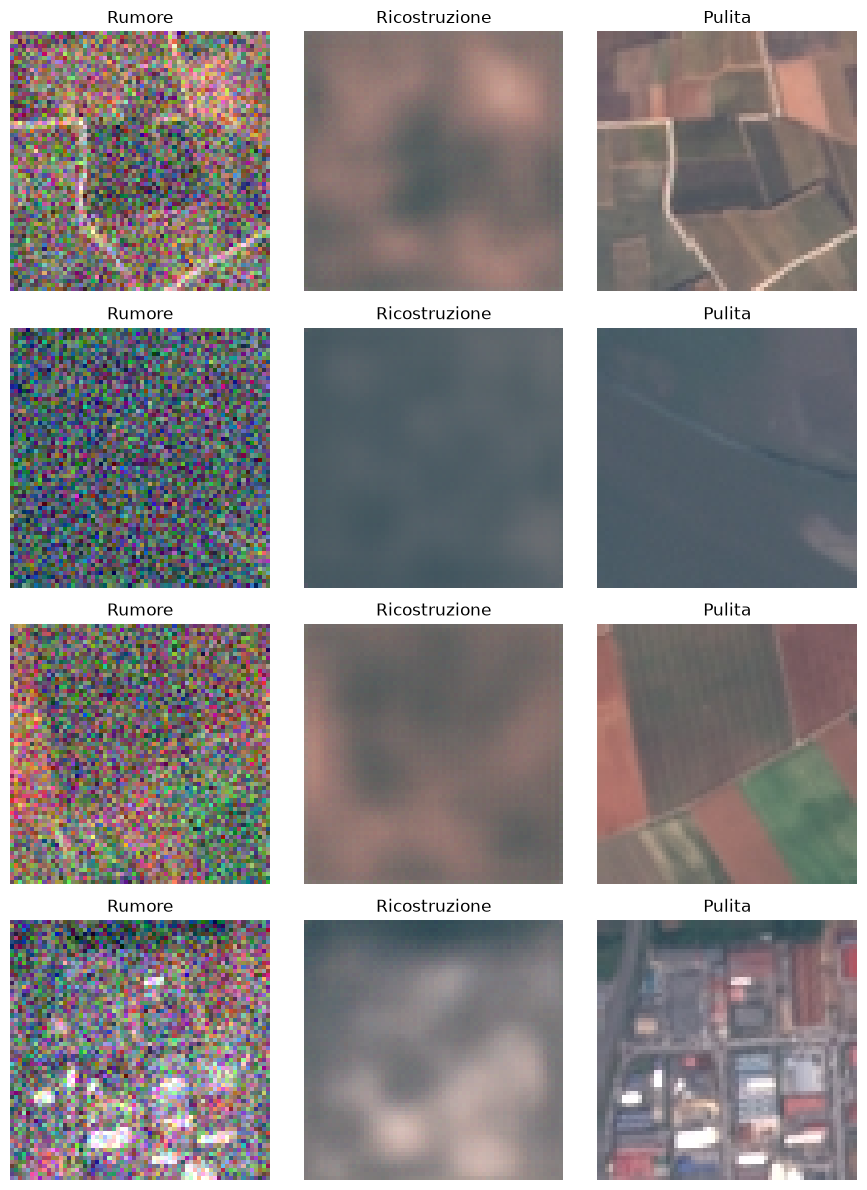

In [7]:
# Valutazione del VAE sul test set con z = mu (valutazione deterministica).
# `evaluate` calcola MSE, PSNR e SSIM senza introdurre casualita' nel test.
result = evaluate(vae, te, DEVICE, vae=True)
print("VAE test:", result)

# Plot qualitativo: rumore -> ricostruzione -> immagine pulita.
# Il dataset restituisce due tensori: input rumoroso e target pulito.
noisy_batch, clean_batch = next(iter(te))
num_examples = min(4, len(noisy_batch))
noisy_batch = noisy_batch[:num_examples].cpu()
clean_batch = clean_batch[:num_examples].cpu()

# sample=False usa la media latente z = mu, quindi la ricostruzione e' riproducibile.
with torch.no_grad():
    recon_batch = vae(noisy_batch.to(DEVICE), sample=False)[0].cpu()

# squeeze=False mantiene sempre la forma [righe, colonne], anche con un solo esempio.
fig, axes = plt.subplots(
    num_examples, 3, figsize=(9, 3 * num_examples), squeeze=False
)
for index in range(num_examples):
    # I tensori sono CHW, mentre Matplotlib richiede il formato HWC.
    axes[index, 0].imshow(noisy_batch[index].permute(1, 2, 0).numpy())
    axes[index, 0].set_title("Rumore")
    axes[index, 0].axis("off")

    axes[index, 1].imshow(recon_batch[index].permute(1, 2, 0).numpy())
    axes[index, 1].set_title("Ricostruzione")
    axes[index, 1].axis("off")

    axes[index, 2].imshow(clean_batch[index].permute(1, 2, 0).numpy())
    axes[index, 2].set_title("Pulita")
    axes[index, 2].axis("off")

plt.tight_layout()
plt.show()
